BIBLIOTECAS

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns 

# Preprocesamiento de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Algoritmos de clasificacion
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


# metricas de clasificacion
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay


PREPROCESADO DE DATOS

In [2]:
df = pd.read_csv('cat_breeds_clean.csv')
display(df)

print('Dimensiones:', df.shape)
print('\nTipos de datos:')
print(df.dtypes)
print('\nValores nulos por columna:')
print(df.isna().sum())
print('\nFilas duplicadas:', df.duplicated().sum())
print('\nResumen de la variable objetivo :')
print(df['Breed'].describe())

df.head()

,Breed,Age_in_years,Age_in_months,Gender,Neutered_or_spayed,Body_length,Weight,Fur_colour_dominant,Fur_pattern,Eye_colour,Allowed_outdoor,Preferred_food,Owner_play_time_minutes,Sleep_time_hours,Country,Latitude,Longitude
0,Angora,0.25,3,female,False,19,2.0,white,solid,blue,False,wet,46,16,France,NaN,5.369780
1,Angora,0.33,4,male,False,19,2.5,white,solid,blue,False,wet,48,16,France,43.611660,3.877710
2,Angora,0.50,6,male,False,20,2.8,black,solid,green,False,wet,41,11,France,44.837789,-0.579180
3,Angora,0.50,6,female,False,21,3.0,white,solid,blue,False,wet,24,8,France,43.611660,3.877710
4,Angora,0.50,6,male,False,21,3.0,red/cream,tabby,green,False,wet,51,10,France,48.864716,2.349014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1066,Maine coon,0.17,2,female,False,15,1.2,white,solid,blue,False,wet,35,20,UK,51.507351,-0.127758
1067,Maine coon,0.17,2,female,False,17,1.0,black,bicolor,blue,False,wet,36,19,UK,51.507351,-0.127758
1068,Maine coon,0.17,2,male,False,14,0.7,red/cream,tabby,blue,False,wet,20,20,UK,51.507351,-0.127758
1069,Maine coon,0.17,2,male,False,16,1.1,red/cream,tabby,green,False,wet,34,19,UK,52.486244,-1.890401


Dimensiones: (1071, 17)

Tipos de datos:
Breed                       object
Age_in_years               float64
Age_in_months                int64
Gender                      object
Neutered_or_spayed            bool
Body_length                  int64
Weight                     float64
Fur_colour_dominant         object
Fur_pattern                 object
Eye_colour                  object
Allowed_outdoor               bool
Preferred_food              object
Owner_play_time_minutes      int64
Sleep_time_hours             int64
Country                     object
Latitude                   float64
Longitude                  float64
dtype: object

Valores nulos por columna:
Breed                      0
Age_in_years               0
Age_in_months              0
Gender                     3
Neutered_or_spayed         0
Body_length                0
Weight                     0
Fur_colour_dominant        0
Fur_pattern                0
Eye_colour                 0
Allowed_outdoor            0
Pre

,Breed,Age_in_years,Age_in_months,Gender,Neutered_or_spayed,Body_length,Weight,Fur_colour_dominant,Fur_pattern,Eye_colour,Allowed_outdoor,Preferred_food,Owner_play_time_minutes,Sleep_time_hours,Country,Latitude,Longitude
0,Angora,0.25,3,female,False,19,2.0,white,solid,blue,False,wet,46,16,France,NaN,5.369780
1,Angora,0.33,4,male,False,19,2.5,white,solid,blue,False,wet,48,16,France,43.611660,3.877710
2,Angora,0.50,6,male,False,20,2.8,black,solid,green,False,wet,41,11,France,44.837789,-0.579180
3,Angora,0.50,6,female,False,21,3.0,white,solid,blue,False,wet,24,8,France,43.611660,3.877710
4,Angora,0.50,6,male,False,21,3.0,red/cream,tabby,green,False,wet,51,10,France,48.864716,2.349014


In [3]:
# Borrar columnas que no nos digan nada
# df = df.drop("columna_a_borrar",axis=1)
#df = df.drop("id",axis=1)
#df = df.drop("Unnamed: 0",axis=1)

# Variables predictoras y variable objetivo
X = df.drop('Breed', axis=1)
y = df['Breed']


# Columnas numéricas y categóricas
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(exclude=['object']).columns

# median = mediana ; mean = media

# Pipelines para preprocesamiento
# primero los NaN les pones la mediana
# después los escalas(media 0) desviación típica 1
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),      
    ('scaler', StandardScaler())                        
])


# si a una fila le falta algo le pones 'most_frequent'
# OHE , min_frequency=20 (tiene que haber al menos 20 para que se cree una columna), 
#  sino lo agrupa en una nueva que se llama 'nombre_columna_infrequent_if_exist'
# ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20)) 
# si quieres que ignore algo:
# ('onehot', OneHotEncoder(handle_unknown='ignore')) 
# para que haga todo:
# ('onehot', OneHotEncoder(sparse_output=False))   
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False))   
])

# Combinamos los transformadores en un ColumnTransformer
# habla entre las cols y los transformadores y lo combina
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

# Dividimos el dataset en entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Muestras para entrenar: {X_train.shape[0]}')
print(f'Muestras para validar: {X_test.shape[0]}')
print(f'Número de variables numéricas: {len(num_cols)}')
print(f'Número de variables categóricas: {len(cat_cols)}')

Muestras para entrenar: 856
Muestras para validar: 215
Número de variables numéricas: 10
Número de variables categóricas: 6


In [4]:

# Para que la salida de de tipo DataFrame y no de tipo NumpyArray y se pueda dibujar
# hay que poner tambien en el constructor sparse_output = False
preprocessor.set_output(transform="pandas")

# Procesa las columnas(numericas y categóricas)
# fit_transformed = aprende las medias y medianas y aplica
# transform = solo aplica con lo que ya has aprendido
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print('Forma del conjunto de entrenamiento tras el preprocesado:', X_train_transformed.shape)
print('Forma del conjunto de prueba tras el preprocesado:', X_test_transformed.shape)
print('Número total de variables generadas:', len(preprocessor.get_feature_names_out()))

feature_names = preprocessor.get_feature_names_out()
print('\nPrimeras 15 variables transformadas:')
print(feature_names[:15])

Forma del conjunto de entrenamiento tras el preprocesado: (856, 35)
Forma del conjunto de prueba tras el preprocesado: (215, 35)
Número total de variables generadas: 35

Primeras 15 variables transformadas:
['num__Age_in_years' 'num__Age_in_months' 'num__Neutered_or_spayed'
 'num__Body_length' 'num__Weight' 'num__Allowed_outdoor'
 'num__Owner_play_time_minutes' 'num__Sleep_time_hours' 'num__Latitude'
 'num__Longitude' 'cat__Gender_female' 'cat__Gender_male'
 'cat__Fur_colour_dominant_black'
 'cat__Fur_colour_dominant_brown/chocolate'
 'cat__Fur_colour_dominant_red/cream']


GRÁFICAS Y DEMÁS

GRÁFICO DE DISPERSIÓN  
Hay que elegir una x y una y tú(está en 2D)

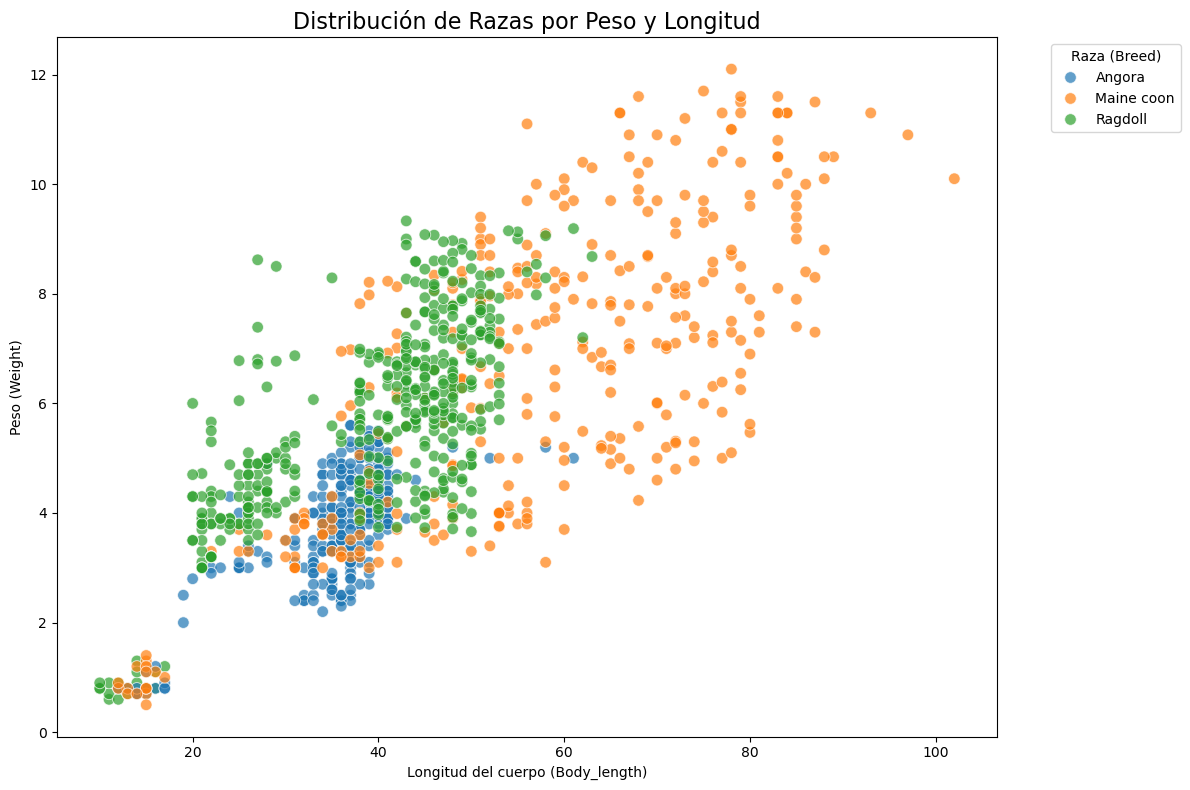

In [5]:

# Creamos un lienzo grande
plt.figure(figsize=(12, 8))

# Dibujamos los puntos
sns.scatterplot(
    data=df, 
    x='Body_length',      # El eje horizontal será la longitud
    y='Weight',           # El eje vertical será el peso
    hue='Breed',          # ¡La magia! Pinta cada punto del color de su Raza
    palette='tab10',      # Una paleta con muchos colores distintos
    s=70,                 # Tamaño del puntito
    alpha=0.7             # Un poco transparentes por si se pisan unos a otros
)

plt.title('Distribución de Razas por Peso y Longitud', fontsize=16)
plt.xlabel('Longitud del cuerpo (Body_length)')
plt.ylabel('Peso (Weight)')

# Movemos la leyenda fuera del gráfico para que no estorbe
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Raza (Breed)')
plt.tight_layout()
plt.show()

GRÁFICO DE BARRAS

C:\Users\Lucas\AppData\Local\Temp\ipykernel_1772\665875550.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Breed', palette='viridis')


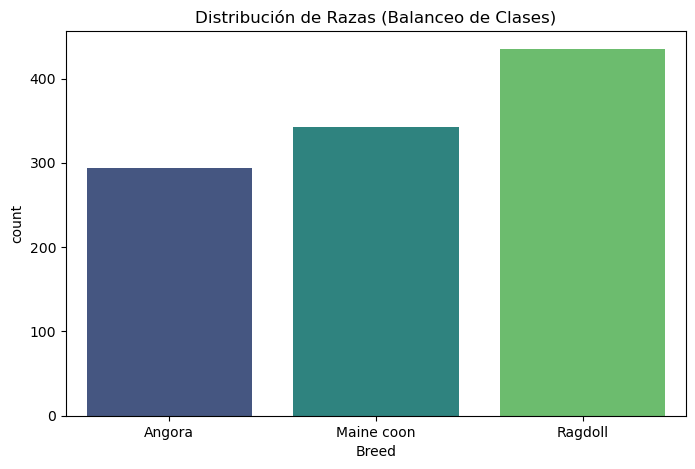

In [17]:

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Breed', palette='viridis')
plt.title('Distribución de Razas (Balanceo de Clases)')
plt.show()

MAPA DE CALOR DE CORRELACIONES

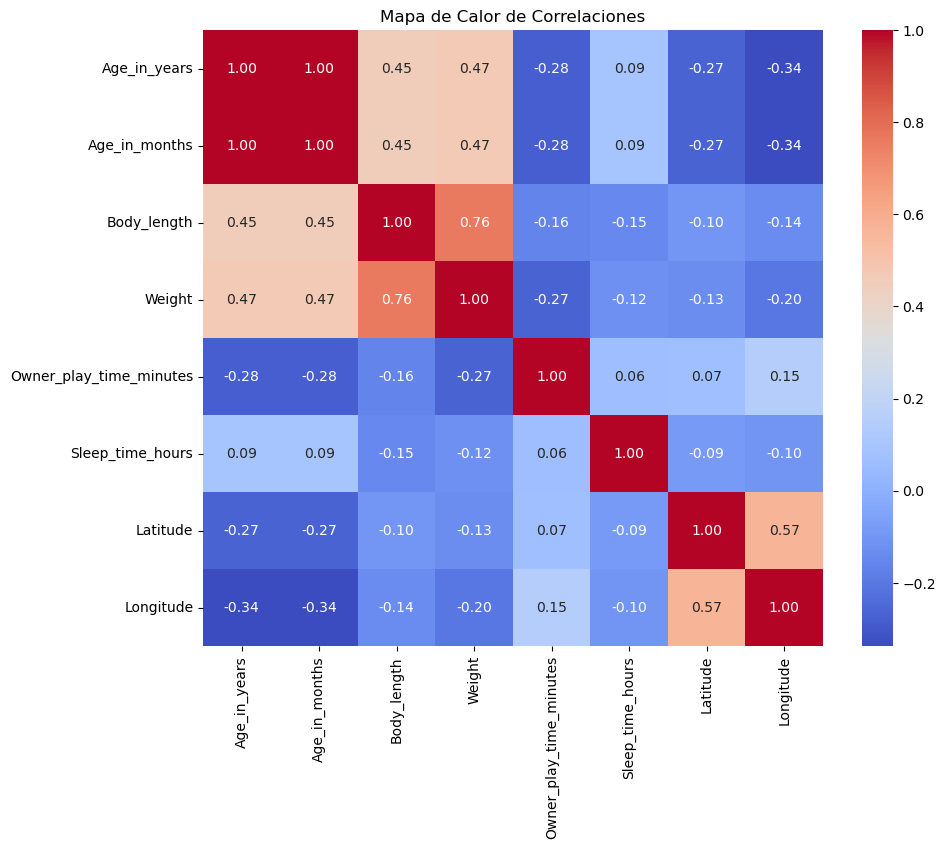

In [18]:
# Ojo: La correlación SOLO se puede hacer con columnas numéricas
columnas_numericas = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10, 8))
sns.heatmap(columnas_numericas.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Mapa de Calor de Correlaciones')
plt.show()

DIAGRAMA DE CAJAS CON BIGOTES  
la caja es un 50%   
la raya en medio es la mediana  
los bigotes es hasta donde se alargan las lineas fuera de la caja, es hasta donde se   
considera que no es un valor atípico  
si es un valor atípico se marca de otra manera(si está fuera del límite de los bigotes)  

C:\Users\Lucas\AppData\Local\Temp\ipykernel_1772\3457239127.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Breed', y='Weight', palette='Set2')


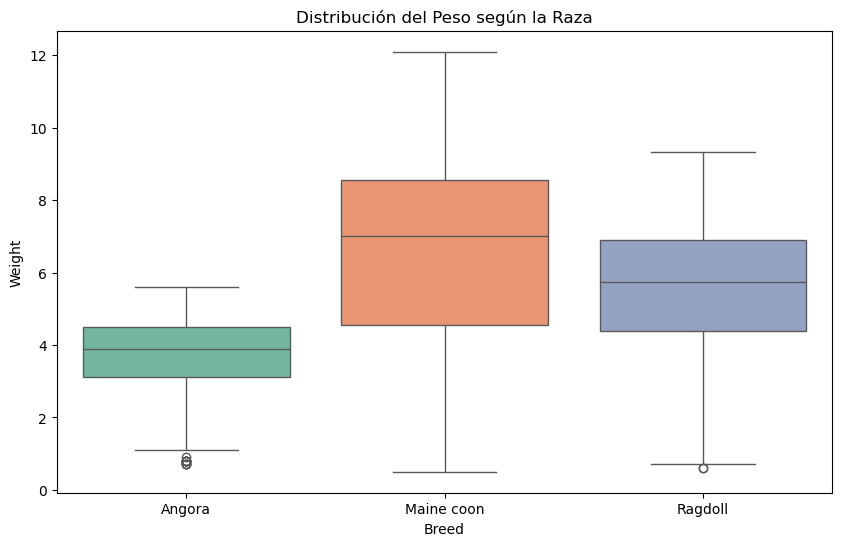

In [19]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Breed', y='Weight', palette='Set2')
plt.title('Distribución del Peso según la Raza')
plt.show()

CLASIFICACIÓN

DECISION TREE

In [7]:
from sklearn.tree import DecisionTreeClassifier

depth = []
accDT = []

for i in range(1,20):
    decision_tree = DecisionTreeClassifier(random_state=0, max_depth=i)
    # Entrenar modelo
    decision_tree.fit(X_train_transformed, y_train)
    # Hacer prediccion
    dt_pred = decision_tree.predict(X_test_transformed)
    # Accuracy
    dt_accuracy = accuracy_score(y_test, dt_pred)
    print("max_depth ",i,"Acc ",dt_accuracy)
    depth.append(i)
    accDT.append(dt_accuracy)
    
dt_accuracyMax = np.argmax(accDT)
print("Accuracy ",accDT[dt_accuracyMax], " with max_depth ",depth[dt_accuracyMax])

decision_tree = DecisionTreeClassifier(random_state=0, max_depth=depth[dt_accuracyMax])
decision_tree.fit(X_train_transformed, y_train)

max_depth  1 Acc  0.6604651162790698
max_depth  2 Acc  0.8
max_depth  3 Acc  0.8883720930232558
max_depth  4 Acc  0.9395348837209302
max_depth  5 Acc  0.9348837209302325
max_depth  6 Acc  0.9441860465116279
max_depth  7 Acc  0.9674418604651163
max_depth  8 Acc  0.958139534883721
max_depth  9 Acc  0.9674418604651163
max_depth  10 Acc  0.9674418604651163
max_depth  11 Acc  0.9534883720930233
max_depth  12 Acc  0.9534883720930233
max_depth  13 Acc  0.9534883720930233
max_depth  14 Acc  0.9534883720930233
max_depth  15 Acc  0.9534883720930233
max_depth  16 Acc  0.9534883720930233
max_depth  17 Acc  0.9534883720930233
max_depth  18 Acc  0.9534883720930233
max_depth  19 Acc  0.9534883720930233
Accuracy  0.9674418604651163  with max_depth  7


,criterion,'gini'
,splitter,'best'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


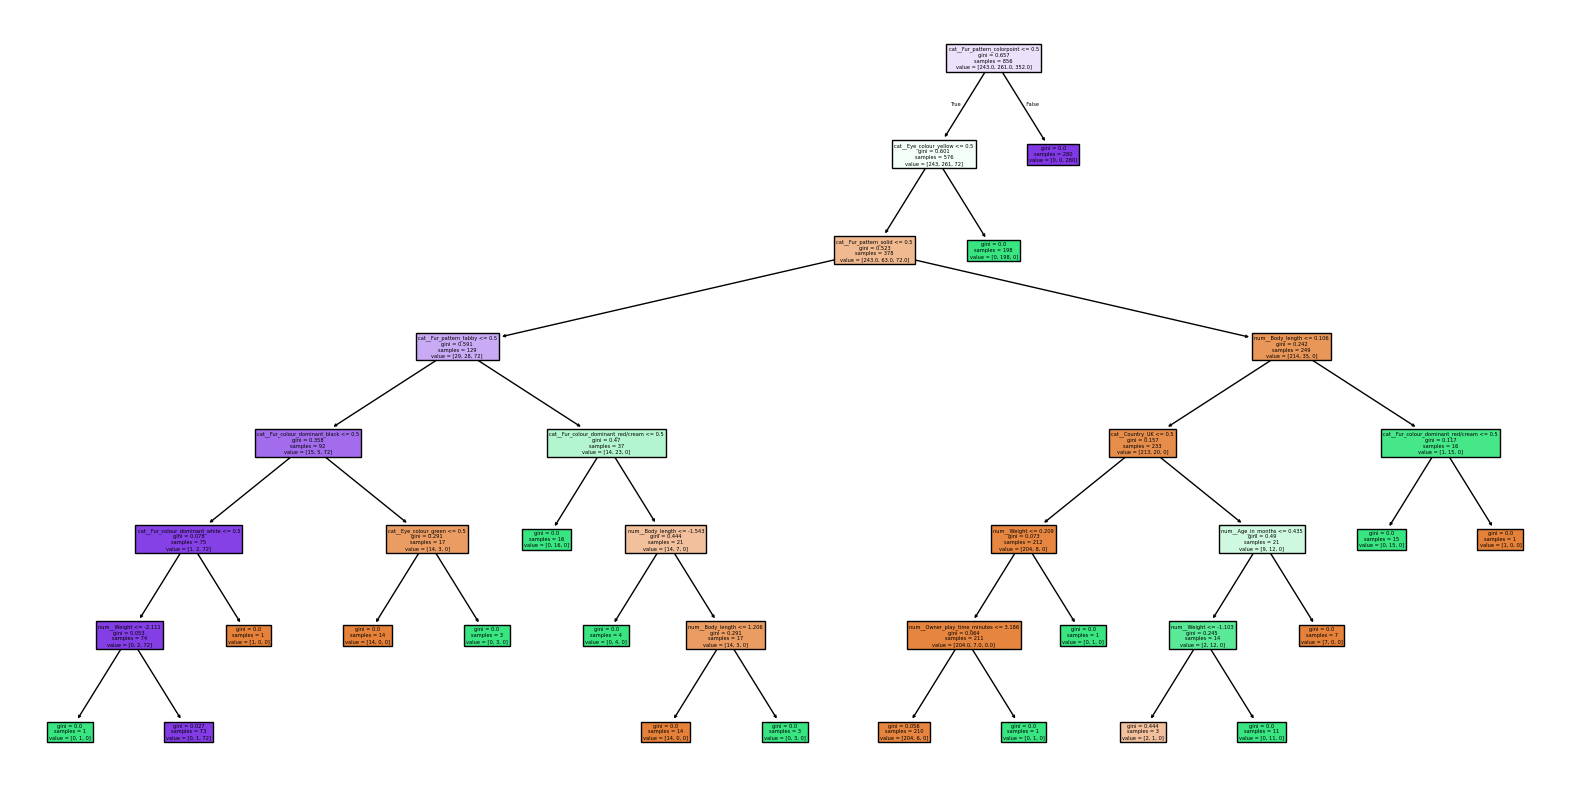

In [8]:
# figura de 20 x 10
plt.figure(figsize=(20,10))
# construirlo
plot_tree(decision_tree, feature_names=X_train_transformed.columns, filled=True)
plt.show()

El mejor arboles de decisiones: 


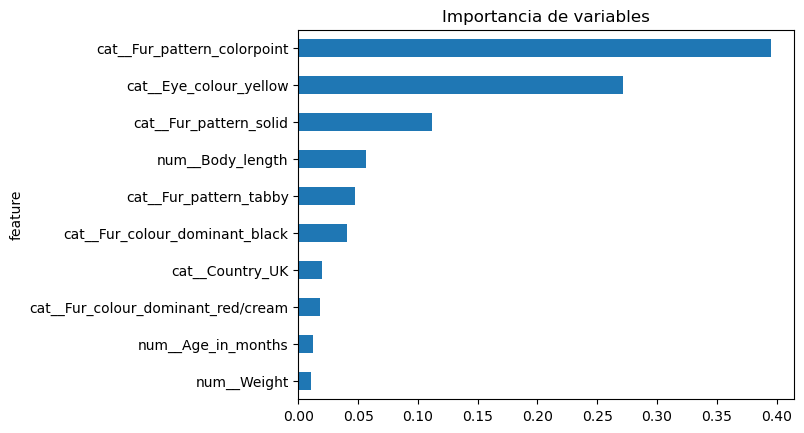

In [9]:
importancias = decision_tree.feature_importances_

df_importancias = pd.DataFrame({
    'feature': X_train_transformed.columns,
    'importance': importancias
}).sort_values(by='importance', ascending=False)

# print(df_importancias)

# Se queda solamente con las 10 primeras filas (el top 10 de las más importantes)
# kind= barh es que sea de barras
# x = features es decirle donde va el eje
# legend = False es para que nos oculte la leyenda (solamente hay un color)
df_importancias.head(10).plot(
    kind='barh', x='feature', y='importance', legend=False
)
# Si no el top 1 estaría abajo del todo
plt.gca().invert_yaxis()
plt.title("Importancia de variables")
print("El mejor arboles de decisiones: ")
plt.show()

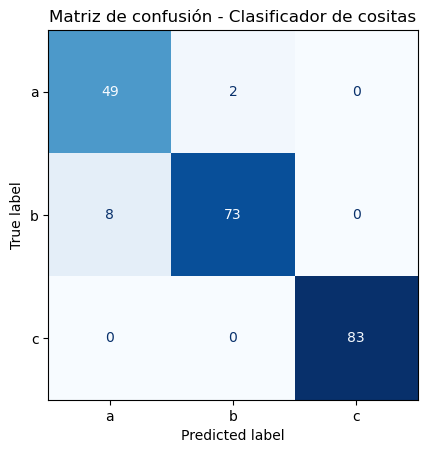

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=['a', 'b', 'c'],
    cmap='Blues',
    colorbar=False
)
plt.title('Matriz de confusión - Clasificador de cositas')
plt.show()

RANDOM FOREST

In [11]:

# n_estimators = número de árboles de decisiones
rfClass = RandomForestClassifier(n_estimators=20,max_depth=9, random_state=0) # construir
rfClass.fit(X_train_transformed, y_train)               # entrenar
y_predictRF = rfClass.predict(X_test_transformed)       # predecir

rf_accuracy = accuracy_score(y_test, y_predictRF)
print("accuracy",rf_accuracy)
print("\nClassification Report:\n", classification_report(y_test, y_predictRF))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_predictRF))

accuracy 0.9674418604651163

Classification Report:
               precision    recall  f1-score   support

      Angora       0.89      1.00      0.94        51
  Maine coon       1.00      0.93      0.96        81
     Ragdoll       0.99      0.99      0.99        83

    accuracy                           0.97       215
   macro avg       0.96      0.97      0.96       215
weighted avg       0.97      0.97      0.97       215

Confusion Matrix:
 [[51  0  0]
 [ 5 75  1]
 [ 1  0 82]]


KNN

In [12]:
from sklearn.neighbors import KNeighborsClassifier

ks = []                     # las k
acc = []                    # la accuaricy de cada k
knnPredictions = []         # las predicciones de cada k

# Probar k E [1, 20]
for i in range(1,4):
    
    # n_neighbors = la k del momento , metric = la metrica que quieras usar
    neigh = KNeighborsClassifier(n_neighbors=i, metric="manhattan")
    neigh.fit(X_train_transformed, y_train)                                 # entreno
    y_predictKNN = neigh.predict(X_test_transformed)                        # prediccion
    knn_accuracy = accuracy_score(y_test, y_predictKNN)         # accuaracy

    knnPredictions.append(y_predictKNN)
    ks.append(i)
    acc.append(knn_accuracy)
    print("K ",i,knn_accuracy)

knnAccuracyMax = np.argmax(acc)
print("Accuracy ",acc[knnAccuracyMax], " with K ",ks[knnAccuracyMax])

K  1 0.9395348837209302
K  2 0.9069767441860465
K  3 0.9441860465116279
Accuracy  0.9441860465116279  with K  3


MVP

In [13]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Tamaño de X_train:", X_train_transformed.shape)
print("Tamaño de y_train:", y_train.shape)

# constructor
mlp = MLPClassifier(
    hidden_layer_sizes=(30, 10), # Dos capas ocultas con 30 y 10 neuronas
    activation='relu',           # Función no lineal
    max_iter=7000,               # Límite de épocas de estudio
    alpha=0.01,                  # Regularización (evita el sobreajuste)
    learning_rate_init=0.001,    # Velocidad de aprendizaje
    random_state=0               # Semilla para que el resultado sea siempre el mismo
)

# entrenar
print("\nEntrenando la red neuronal...")
mlp.fit(X_train_transformed, y_train)

# predecir
print("Haciendo la predicción a los datos...")
y_pred = mlp.predict(X_test_transformed)

# resultados
accuracy = accuracy_score(y_test, y_pred)

print("\n=== RESULTADOS DEL MODELO ===")
print("Accauricy: ", accuracy)
print(f"Accuracy (Porcentaje de acierto): {accuracy * 100:.2f}%\n")

print("Matriz de Confusión:")
print(confusion_matrix(y_test, y_pred))

Tamaño de X_train: (856, 35)
Tamaño de y_train: (856,)

Entrenando la red neuronal...
Haciendo la predicción a los datos...

=== RESULTADOS DEL MODELO ===
Accauricy:  0.9767441860465116
Accuracy (Porcentaje de acierto): 97.67%

Matriz de Confusión:
[[51  0  0]
 [ 4 77  0]
 [ 0  1 82]]


SVM SIMPLE

In [14]:
'''
# Support Vector Classification




# Crear y entrenar una SVM simple
# kernel .= tipo de kernel
# C .= parámetro de regularización(cuánto le debe importar los errores) ; 1 es lo normal
# random_state .= semilla
svm_simple = SVC(kernel='linear', C=1.0, random_state=13)

svm_simple.fit(X_train_transformed, y_train)

# Predicciones
y_pred_svm_simple = svm_simple.predict(X_test_transformed)

# Accuracy
accuracy_svm_simple = accuracy_score(y_test, y_pred_svm_simple)
print(f"\nSVM lineal Accuracy: {accuracy_svm_simple * 100:.2f}%")

# Métricas
print("\nClassification Report (SVM lineal):\n")
print(classification_report(y_test, y_pred_svm_simple))

print("\nMatriz de Confusión (SVM lineal):\n")
print(confusion_matrix(y_test, y_pred_svm_simple))
'''

'\n# Support Vector Classification\n\n\n\n\n# Crear y entrenar una SVM simple\n# kernel .= tipo de kernel\n# C .= parámetro de regularización(cuánto le debe importar los errores) ; 1 es lo normal\n# random_state .= semilla\nsvm_simple = SVC(kernel=\'linear\', C=1.0, random_state=13)\n\nsvm_simple.fit(X_train_transformed, y_train)\n\n# Predicciones\ny_pred_svm_simple = svm_simple.predict(X_test_transformed)\n\n# Accuracy\naccuracy_svm_simple = accuracy_score(y_test, y_pred_svm_simple)\nprint(f"\nSVM lineal Accuracy: {accuracy_svm_simple * 100:.2f}%")\n\n# Métricas\nprint("\nClassification Report (SVM lineal):\n")\nprint(classification_report(y_test, y_pred_svm_simple))\n\nprint("\nMatriz de Confusión (SVM lineal):\n")\nprint(confusion_matrix(y_test, y_pred_svm_simple))\n'

SVM NO LINEAL

In [15]:
'''
# Crear y entrenar el modelo SVM
# al no decir el tipo de kernel, por defecto usa el 'rbf' que es no linear
svm = SVC(random_state=13)
# svm = SVC(C=1.0, kernel='rbf', gamma='scale', random_state=13)

# OJO: Usamos X_train_transformed y X_test_transformed generados en el paso 5.1
svm.fit(X_train_transformed, y_train)

# Hacer predicciones con el modelo SVM
y_pred_svm = svm.predict(X_test_transformed)

# Evaluar el modelo SVM
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"\nSVM Accuracy: {accuracy_svm * 100:.2f}%")

# Reportes detallados
print("\nClassification Report (SVM):\n", classification_report(y_test, y_pred_svm))
print("\nMatriz de Confusión (SVM):\n", confusion_matrix(y_test, y_pred_svm))

'''

'\n# Crear y entrenar el modelo SVM\n# al no decir el tipo de kernel, por defecto usa el \'rbf\' que es no linear\nsvm = SVC(random_state=13)\n# svm = SVC(C=1.0, kernel=\'rbf\', gamma=\'scale\', random_state=13)\n\n# OJO: Usamos X_train_transformed y X_test_transformed generados en el paso 5.1\nsvm.fit(X_train_transformed, y_train)\n\n# Hacer predicciones con el modelo SVM\ny_pred_svm = svm.predict(X_test_transformed)\n\n# Evaluar el modelo SVM\naccuracy_svm = accuracy_score(y_test, y_pred_svm)\nprint(f"\nSVM Accuracy: {accuracy_svm * 100:.2f}%")\n\n# Reportes detallados\nprint("\nClassification Report (SVM):\n", classification_report(y_test, y_pred_svm))\nprint("\nMatriz de Confusión (SVM):\n", confusion_matrix(y_test, y_pred_svm))\n\n'